# Лабораторна робота № 2

## Оптимізаційна задача та аналіз чутливості

**Дисципліна:** Інтелектуальний аналіз та візуалізація даних (СК26)
**Тривалість:** 2 год аудиторно + 3 год самостійної роботи * **Максимальна оцінка:** 4 бали

---

### Мета роботи

Побудувати оптимізаційну модель у двох середовищах, прочитати звіт про стійкість
і **ухвалити на його основі господарське рішення**.

Розв'язати задачу — не мета. Solver зробить це за дві секунди. Робота оцінюється за
те, що ви зумієте зі звіту витягнути.

### Дві частини

| Частина | Задача | Де виконується |
|---|---|---|
| **1** | виробнича задача — Excel і Python | аудиторно |
| **2** | транспортна задача — Python | самостійно |

Друга частина потрібна не для повторення. Там та сама методика поводиться інакше,
і ви маєте побачити, де саме проходить межа її застосовності.

### Що здається

1. Цей файл `.ipynb` із заповненими розв'язками. **Виконується згори донизу на чистому
   ядрі** (Kernel → Restart & Run All) без помилок — перевіряється першою дією на захисті.
2. Файл Excel з моделлю, налаштуваннями Solver і **звітом про стійкість** окремим аркушем.
3. Заповнена декларація про використання ШІ (етап 12).

### Оцінювання

| Бали | Що досягнуто |
|---|---|
| 0 | Модель не сформульовано або розв'язок не отримано |
| 1 | Розв'язок отримано лише в одному середовищі, звіт про стійкість не проаналізовано |
| 2 | Задачу розв'язано в обох середовищах і звіти зіставлено, але тіньові ціни та діапазони не інтерпретовано |
| 4 | Звіт прочитано й перевірено експериментом, ухвалено обґрунтоване рішення про закупівлю, виконано частину 2 з поясненням розбіжності |

---
## Крок 0. Ваші дані та варіант

In [1]:
ПІБ = 'Левченко Денис'        # напр. 'Шевченко Тарас'
ГРУПА = 'ШІ-33'      # напр. 'КН-31'
ВАРІАНТ = 4     # ваш номер за списком групи

assert ПІБ and ГРУПА and 1 <= ВАРІАНТ <= 30, 'Заповніть ПІБ, ГРУПУ та ВАРІАНТ (1..30)'

In [2]:
# --- клітинку не редагувати: вона видає дані вашого варіанта -----------------
import json, numpy as np, pandas as pd

ДАНІ_ВАРІАНТІВ = json.loads('''{"1": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[0, 2, 1, 1], [3, 3, 0, 6], [2, 3, 0, 2], [4, 6, 0, 5], [3, 1, 5, 4]], "c": [21, 69, 44, 39], "b": [929, 410, 507, 865, 425], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.2, "обсяг_пропозиції": 44}, "2": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 2, 5, 2], [6, 5, 4, 2], [5, 2, 0, 3], [2, 1, 5, 0], [5, 5, 6, 2]], "c": [40, 66, 24, 34], "b": [1271, 702, 915, 1388, 804], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.7, "обсяг_пропозиції": 204}, "3": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 2, 6, 6], [3, 4, 3, 6], [1, 6, 6, 0], [3, 1, 6, 1], [4, 1, 1, 4]], "c": [51, 16, 34, 22], "b": [1189, 686, 1311, 512, 1030], "ресурс_пропозиції": 3, "ціна_пропозиції": 11.3, "обсяг_пропозиції": 348}, "4": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 0, 0, 0], [1, 0, 5, 2], [2, 4, 6, 5], [3, 0, 5, 3], [2, 1, 2, 5]], "c": [41, 50, 54, 26], "b": [815, 344, 840, 840, 382], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.3, "обсяг_пропозиції": 144}, "5": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 0, 6, 6], [3, 2, 2, 4], [5, 5, 0, 6], [2, 1, 5, 3], [5, 5, 4, 2]], "c": [32, 66, 25, 24], "b": [874, 1034, 1349, 845, 1394], "ресурс_пропозиції": 2, "ціна_пропозиції": 8.6, "обсяг_пропозиції": 90}, "6": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[3, 2, 1, 4], [4, 2, 2, 1], [3, 5, 1, 2], [3, 2, 0, 2], [6, 4, 6, 3]], "c": [40, 62, 19, 57], "b": [630, 391, 1349, 811, 1085], "ресурс_пропозиції": 1, "ціна_пропозиції": 29.5, "обсяг_пропозиції": 268}, "7": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[0, 0, 5, 5], [4, 4, 0, 1], [2, 4, 0, 6], [6, 3, 4, 1], [2, 2, 1, 0]], "c": [20, 59, 63, 41], "b": [1189, 1189, 1217, 915, 424], "ресурс_пропозиції": 3, "ціна_пропозиції": 8.0, "обсяг_пропозиції": 314}, "8": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[2, 1, 3, 5], [3, 1, 0, 6], [1, 6, 1, 5], [2, 2, 4, 0], [6, 1, 2, 2]], "c": [60, 25, 59, 25], "b": [1279, 761, 376, 1230, 1065], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.5, "обсяг_пропозиції": 234}, "9": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 2, 1, 2], [5, 0, 1, 3], [5, 4, 6, 4], [4, 1, 1, 5], [6, 0, 3, 0]], "c": [58, 39, 54, 16], "b": [1147, 1199, 1280, 404, 1170], "ресурс_пропозиції": 2, "ціна_пропозиції": 6.1, "обсяг_пропозиції": 672}, "10": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 0, 4, 3], [0, 6, 0, 6], [5, 5, 3, 5], [6, 2, 3, 3], [3, 0, 0, 4]], "c": [20, 29, 37, 63], "b": [905, 344, 866, 1390, 355], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.3, "обсяг_пропозиції": 78}, "11": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 3], [3, 1, 4, 0], [1, 0, 3, 2], [3, 2, 2, 6], [3, 6, 0, 3]], "c": [30, 16, 51, 35], "b": [1312, 838, 1062, 1038, 1236], "ресурс_пропозиції": 1, "ціна_пропозиції": 15.6, "обсяг_пропозиції": 778}, "12": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 2, 0, 5], [1, 1, 3, 6], [6, 3, 5, 4], [2, 4, 6, 0], [4, 6, 2, 4]], "c": [39, 55, 36, 26], "b": [788, 661, 458, 1005, 535], "ресурс_пропозиції": 4, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 762}, "13": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[1, 5, 3, 0], [6, 4, 6, 3], [4, 4, 4, 1], [0, 3, 5, 3], [3, 5, 3, 3]], "c": [59, 42, 53, 19], "b": [937, 1390, 603, 1120, 1334], "ресурс_пропозиції": 2, "ціна_пропозиції": 15.1, "обсяг_пропозиції": 646}, "14": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 3, 3, 4], [6, 6, 1, 6], [1, 3, 5, 1], [1, 5, 1, 4], [4, 4, 0, 3]], "c": [26, 56, 41, 40], "b": [969, 672, 1364, 878, 618], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 222}, "15": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 3, 3, 1], [2, 5, 6, 6], [3, 1, 0, 0], [0, 4, 4, 6], [2, 2, 2, 6]], "c": [64, 58, 34, 63], "b": [613, 316, 1035, 739, 810], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.4, "обсяг_пропозиції": 354}, "16": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[1, 6, 4, 2], [4, 1, 1, 2], [4, 4, 6, 6], [5, 6, 3, 3], [1, 2, 4, 2]], "c": [33, 40, 58, 17], "b": [412, 1005, 996, 599, 390], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.2, "обсяг_пропозиції": 44}, "17": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[2, 6, 0, 3], [2, 5, 5, 3], [6, 0, 4, 5], [1, 3, 6, 2], [0, 1, 4, 4]], "c": [33, 52, 20, 66], "b": [989, 1079, 873, 1327, 1224], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.9, "обсяг_пропозиції": 402}, "18": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 3, 0, 1], [0, 6, 1, 6], [1, 0, 4, 1], [2, 6, 3, 4], [3, 1, 6, 5]], "c": [66, 54, 18, 66], "b": [1217, 668, 923, 1040, 619], "ресурс_пропозиції": 4, "ціна_пропозиції": 34.9, "обсяг_пропозиції": 100}, "19": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 2], [3, 3, 4, 5], [2, 1, 0, 4], [4, 1, 5, 0], [0, 3, 6, 3]], "c": [67, 52, 41, 40], "b": [315, 617, 815, 423, 1193], "ресурс_пропозиції": 1, "ціна_пропозиції": 9.3, "обсяг_пропозиції": 332}, "20": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 4, 5, 1], [2, 0, 5, 4], [4, 0, 2, 3], [3, 3, 4, 3], [4, 4, 5, 2]], "c": [42, 63, 35, 56], "b": [1191, 331, 685, 1275, 971], "ресурс_пропозиції": 4, "ціна_пропозиції": 12.2, "обсяг_пропозиції": 604}, "21": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 3, 6], [4, 4, 3, 2], [4, 4, 4, 0], [1, 1, 5, 3], [0, 2, 6, 5]], "c": [32, 66, 26, 64], "b": [464, 393, 354, 597, 887], "ресурс_пропозиції": 0, "ціна_пропозиції": 9.4, "обсяг_пропозиції": 190}, "22": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[6, 0, 2, 6], [3, 4, 0, 4], [4, 3, 1, 5], [5, 5, 6, 2], [2, 0, 1, 5]], "c": [65, 36, 50, 63], "b": [891, 1247, 613, 1070, 1259], "ресурс_пропозиції": 2, "ціна_пропозиції": 13.6, "обсяг_пропозиції": 64}, "23": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[1, 2, 4, 6], [4, 6, 2, 5], [0, 5, 3, 1], [0, 0, 5, 1], [5, 4, 0, 5]], "c": [15, 35, 49, 23], "b": [1251, 637, 304, 629, 923], "ресурс_пропозиції": 2, "ціна_пропозиції": 10.9, "обсяг_пропозиції": 146}, "24": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[3, 2, 6, 1], [0, 2, 5, 6], [2, 4, 4, 0], [5, 6, 2, 5], [2, 4, 2, 1]], "c": [45, 61, 59, 38], "b": [927, 1384, 1294, 798, 323], "ресурс_пропозиції": 4, "ціна_пропозиції": 20.5, "обсяг_пропозиції": 110}, "25": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 4, 4], [2, 1, 4, 1], [3, 1, 4, 4], [1, 4, 2, 0], [6, 4, 6, 6]], "c": [35, 27, 63, 61], "b": [1399, 843, 308, 1393, 713], "ресурс_пропозиції": 2, "ціна_пропозиції": 7.7, "обсяг_пропозиції": 334}, "26": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 1, 4, 4], [3, 1, 5, 0], [6, 3, 6, 3], [1, 3, 6, 1], [6, 4, 5, 2]], "c": [46, 57, 60, 39], "b": [513, 1330, 796, 406, 1258], "ресурс_пропозиції": 3, "ціна_пропозиції": 18.1, "обсяг_пропозиції": 448}, "27": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 6, 0], [6, 5, 6, 0], [5, 2, 3, 0], [6, 4, 3, 6], [6, 0, 0, 3]], "c": [24, 61, 50, 57], "b": [1179, 1358, 417, 463, 610], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.0, "обсяг_пропозиції": 742}, "28": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[4, 5, 6, 2], [6, 4, 2, 1], [0, 5, 4, 3], [6, 6, 3, 3], [4, 4, 4, 1]], "c": [37, 41, 30, 29], "b": [514, 461, 378, 834, 488], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.5, "обсяг_пропозиції": 174}, "29": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 5, 0, 5], [6, 0, 6, 1], [5, 2, 2, 3], [0, 3, 0, 1], [4, 5, 5, 0]], "c": [33, 57, 58, 62], "b": [820, 523, 670, 977, 1074], "ресурс_пропозиції": 0, "ціна_пропозиції": 15.2, "обсяг_пропозиції": 570}, "30": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 1, 4, 0], [6, 5, 1, 4], [5, 6, 1, 4], [1, 2, 6, 0], [1, 0, 3, 1]], "c": [51, 44, 69, 55], "b": [379, 620, 1256, 502, 414], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.9, "обсяг_пропозиції": 230}}''')

V = ДАНІ_ВАРІАНТІВ[str(ВАРІАНТ)]
A = np.array(V['A'], float)          # витрати ресурсу i на один виріб j
c = np.array(V['c'], float)          # прибуток з одного виробу
b = np.array(V['b'], float)          # запас ресурсу на плановий період
вироби, ресурси = V['вироби'], V['ресурси']

print('ВАРІАНТ %d * %s, %s, %s' % (ВАРІАНТ, ПІБ, ГРУПА, V['фірма']))
print('=' * 78)
print('Підприємство %s виготовляє %s. Одиниця виміру плану: %s.' % (V['фірма'], V['що'], V['од']))
print()
таб = pd.DataFrame(A, index=ресурси, columns=вироби).astype(int)
таб['ЗАПАС'] = b.astype(int)
print(таб.to_string())
print()
print(pd.DataFrame([c.astype(int)], index=['Прибуток з одиниці'], columns=вироби).to_string())
print()
print('ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)')
print('  ресурс: %s' % ресурси[V['ресурс_пропозиції']])
print('  ціна:   %.1f за одиницю' % V['ціна_пропозиції'])
print('  обсяг:  до %d одиниць' % V['обсяг_пропозиції'])

ВАРІАНТ 4 * Левченко Денис, ШІ-33, «Друк-Сервіс»
Підприємство «Друк-Сервіс» виготовляє поліграфію. Одиниця виміру плану: тис. прим./тиждень.

                          Буклет  Каталог  Календар  Плакат  ЗАПАС
Крейдований папір, кг          5        0         0       0    815
Офсетний папір, кг             1        0         5       2    344
Фарба, кг                      2        4         6       5    840
Друкарська машина, год         3        0         5       3    840
Різка й фальцювання, год       2        1         2       5    382

                    Буклет  Каталог  Календар  Плакат
Прибуток з одиниці      41       50        54      26

ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)
  ресурс: Різка й фальцювання, год
  ціна:   8.3 за одиницю
  обсяг:  до 144 одиниць


In [3]:
import matplotlib.pyplot as plt
try:
    import pulp
    ПУЛП = True
except ImportError:
    ПУЛП = False
    print('pulp не встановлено — скористайтеся scipy.optimize.linprog')
from scipy.optimize import linprog

pd.set_option('display.width', 180)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9})

---
# ЧАСТИНА 1. Виробнича задача

# Етап 1. Формалізація

Перш ніж будувати таблицю, запишіть модель словами й формулами. Це найважливіші
двадцять хвилин роботи: помилку тут не виправить жодна кнопка.

### Завдання 1.1
Заповніть у клітинці нижче:

* **змінні рішення** — що саме ви обираєте і в яких одиницях;
* **цільова функція** — що робите найбільшим, з коефіцієнтами вашого варіанта;
* **обмеження** — по одному рядку на кожен ресурс, з числами вашого варіанта;
* **умови невід'ємності**.

Пишіть формулами, а не описом. Приклад запису одного обмеження:
`8*x1 + 4*x2 + 0*x3 + 2*x4 ≤ 1280   (конвеєр A)`

**Відповідь 1.1 — символічна модель**

Змінні рішення: x1 - Буклет, x2 - Каталог, x3 - Календар, x4 - Плакат

Цільова функція: (41*x1 + 50*x2 + 54*x3 + 26*x4) -> max

Обмеження: 5*x1 + 0*x2 + 0*x3 + 0*x4 ≤ 815   (крейдований папір, кг)
1*x1 + 0*x2 + 5*x3 + 2*x4 ≤ 344   (офсетний папір, кг)
2*x1 + 4*x2 + 6*x3 + 5*x4 ≤ 840   (фарба, кг)
3*x1 + 0*x2 + 5*x3 + 3*x4 ≤ 840   (друкарська машина, год)
2*x1 + 1*x2 + 2*x3 + 5*x4 ≤ 382   (різка й фальцювання, год)

Невід'ємність: x1, x2, x3, x4 ≥ 0


### Завдання 1.2 — питання на розуміння
Чому запас ресурсу — це **параметр**, а не змінна рішення? Що змінилося б у моделі,
якби підприємство могло докупити ресурс у будь-якій кількості?

**Відповідь 1.2:** Параметр тому, що запас є  на складі і ми його не можем вибирати. Якби можна було докупити ресурс в будь-якій кількості, тоді якщо він необмежений і безкоштовний то задача стає необмеженою, а якщо його продають за якусь ціну то додалась би нова змінна і було б вигідно докупляти ресурс до тих пір, поки він не стане дорожчим за користь від його використання.

---
# Етап 2. Розв'язання в Excel

1. Побудуйте табличну модель: окремо клітинки змінних рішення, окремо витрати ресурсів,
   окремо цільова функція. Не змішуйте вхідні дані з формулами.
2. Налаштуйте **Пошук рішення (Solver)**: цільова клітинка на максимум, клітинки змінних,
   обмеження по кожному ресурсу, невід'ємність, метод «Симплекс-метод для лінійних задач».
3. Отримайте розв'язок і **обов'язково замовте «Звіт про стійкість»** окремим аркушем.

**Що подати:** файл Excel зі скріншотом налаштувань Solver, оптимальним планом і звітом.

### Завдання 2.1
Перенесіть результат Excel у клітинку нижче — його порівняємо з Python.

In [4]:
# впишіть числа, які дав Excel
EXCEL_ПЛАН    = [114.6667, 152.6667, 0, 0]     # оптимальний випуск кожного виробу
EXCEL_ПРИБУТОК = 12334.67             # значення цільової функції

print('Excel:', EXCEL_ПЛАН, '| прибуток', EXCEL_ПРИБУТОК)

Excel: [114.6667, 152.6667, 0, 0] | прибуток 12334.67


---
# Етап 3. Розв'язання в Python

### Завдання 3.1
Побудуйте ту саму модель у Python і розв'яжіть її. Можна `pulp`, можна
`scipy.optimize.linprog` — на ваш вибір.

*Очікуваний результат: оптимальний план і значення цільової функції.*

**Увага на знак.** `linprog` завжди мінімізує. Щоб максимізувати прибуток, передають
`-c`, а результат беруть як `-r.fun`.

In [5]:
# ВАШ КОД
r = linprog(-c, A_ub=A, b_ub=b, bounds=[(0, None)] * len(c), method='highs')
assert r.status == 0, r.message        

план = r.x
прибуток = -r.fun

print('Прибуток: %.4f' % прибуток)
display(pd.Series(план.round(4), index=вироби, name='випуск'))
display(pd.DataFrame({'витрачено': (A @ план).round(4),
                      'запас': b,
                      'залишок': (b - A @ план).round(4)}, index=ресурси))


Прибуток: 12334.6667


Буклет      114.6667
Каталог     152.6667
Календар      0.0000
Плакат        0.0000
Name: випуск, dtype: float64

,витрачено,запас,залишок
"Крейдований папір, кг",573.3333,815.0,241.6667
"Офсетний папір, кг",114.6667,344.0,229.3333
"Фарба, кг",840.0000,840.0,0.0000
"Друкарська машина, год",344.0000,840.0,496.0000
"Різка й фальцювання, год",382.0000,382.0,0.0000


**Самоперевірка етапу 3.** Excel і Python мають дати той самий результат.

In [6]:
assert план is not None and прибуток is not None, 'спершу розв’яжіть задачу'
assert abs(прибуток - EXCEL_ПРИБУТОК) < 0.5, (
    'Excel дав %.2f, Python %.2f — знайдіть, де розбіжність' % (EXCEL_ПРИБУТОК, прибуток))
assert np.allclose(np.array(план, float), np.array(EXCEL_ПЛАН, float), atol=0.5), \
    'плани не збігаються — перевірте обмеження'
print('Етап 3 пройдено: обидва середовища дали однаковий результат')

Етап 3 пройдено: обидва середовища дали однаковий результат


---
# Етап 4. Читання звіту про стійкість

Звіт Excel має два блоки. Заповніть обидві таблиці — беріть числа зі **звіту**,
а не з власних обчислень.

### Завдання 4.1 — блок «Обмеження»

| Ресурс | Кінцеве значення | Тіньова ціна | Права частина | Допустиме збільшення | Допустиме зменшення |
|---|---|---|---|---|---|
| Крейдований папір, кг | 573.33 | 0 | 815 | 1E+30 | 241.67 |
| Офсетний папір, кг | 114.67 | 0 | 344 | 1E+30 | 229.33 |
| Фарба, кг | 840 | 9.8333 | 840 | 688 | 290 |
| Друкарська машина, год | 344 | 0 | 840 | 1E+30 | 496 |
| Різка й фальцювання, год | 382 | 10.6667 | 382 | 72.5 | 172 |

**Які ресурси в дефіциті, а які в надлишку? Як ви це визначили?**

у дефіциті фарба і різка й фальцювання, бо в них кінцеве значення дорівнює правій частині (840 = 840, 382 = 382) і тіньова ціна більша за нуль (9.83 і 10.67), а крейдований папір, офсетний папір і друкарська машина в надлишку, бо їх витрачено менше за запас і тіньова ціна в них 0.


### Завдання 4.2 — блок «Змінні»

| Виріб | Кінцеве значення | Зведена вартість | Цільовий коефіцієнт | Допустиме збільшення | Допустиме зменшення |
|---|---|---|---|---|---|
| Буклет | 114.6667 | 0 | 41 | 59 | 16 |
| Каталог | 152.6667 | 0 | 50 | 32 | 19.75 |
| Календар | 0 | −26.3333 | 54 | 26.3333 | 1E+30 |
| Плакат | 0 | −76.5 | 26 | 76.5 | 1E+30 |

**У вашому варіанті принаймні один виріб не виробляється зовсім.**
Який саме, і на скільки мусив би зрости прибуток з його одиниці, щоб він увійшов у план?
Звідки ви взяли це число?

не виробляються Календар і Плакат, і щоб увійти в план, прибуток з одиниці Календаря має зрости більш ніж на 26.33 (з 54 до 80.33), а Плаката — більш ніж на 76.5 (з 26 до 102.5), ці числа я взяв зі стовпця «Зведена вартість» звіту (вони ж стоять у «Допустиме збільшення»).


---
# Етап 5. Перевірка звіту експериментом

Звіт стверджує, що тіньова ціна дорівнює певному числу і чинна в певних межах.
Excel просто повідомляє ці числа. Python дозволяє їх **перевірити**.

### Завдання 5.1
Візьміть найдорожчий за тіньовою ціною ресурс. Збільште його запас **на одну одиницю**,
розв'яжіть задачу заново і порівняйте приріст прибутку з тіньовою ціною зі звіту.

In [7]:
ТІНЬОВА_ЗІ_ЗВІТУ = 10.6667
ДОПУСТИМЕ_ЗБІЛЬШЕННЯ = 72.5

def макс_прибуток(запаси_ресурсів):
    """Розв'язує ту саму задачу з іншими запасами і повертає максимальний прибуток."""
    rr = linprog(-c, A_ub=A, b_ub=запаси_ресурсів, bounds=[(0, None)] * len(c), method='highs')
    return -rr.fun

тіньові = -r.ineqlin.marginals          
i = int(np.argmax(тіньові))              
b_плюс = b.copy()
b_плюс[i] += 1                           
прибуток_плюс = макс_прибуток(b_плюс)
приріст = прибуток_плюс - прибуток

print('Ресурс:                %s' % ресурси[i])
print('Запас:                 %.0f -> %.0f' % (b[i], b_плюс[i]))
print('Прибуток:              %.4f -> %.4f' % (прибуток, прибуток_плюс))
print('Приріст прибутку:      %.4f' % приріст)
print('Тіньова ціна зі звіту: %.4f' % ТІНЬОВА_ЗІ_ЗВІТУ)

Ресурс:                Різка й фальцювання, год
Запас:                 382 -> 383
Прибуток:              12334.6667 -> 12345.3333
Приріст прибутку:      10.6667
Тіньова ціна зі звіту: 10.6667


**Відповідь 5.1:** збільшив запас різки й фальцювання з 382 до 383 год, і прибуток зріс з 12334.67 до 12345.33, тобто на 10.6667, що точно збігається з тіньовою ціною зі звіту 10.6667.

### Завдання 5.2
Тепер знайдіть **межу діапазону**. Прогоніть задачу для запасу цього ресурсу від
базового значення і далі вгору з кроком 1, побудуйте графік прибутку і графік його
приросту (нахилу).

*Очікуваний результат: два графіки один під одним. На нижньому має бути видно
горизонтальну ділянку на рівні тіньової ціни, а потім злам.*

Приріст = тіньовій ціні від 382 до 454, злам між 454 і 455
Межа за звітом Excel:  382 + 72.5 = 454.5


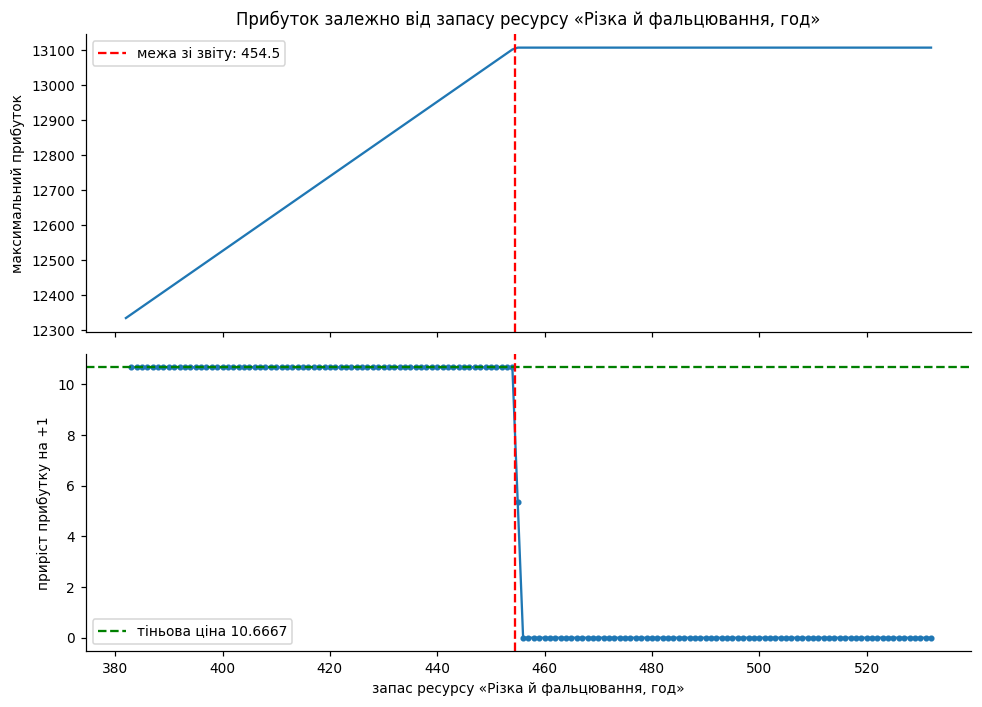

In [8]:
запаси = np.arange(b[i], b[i] + 151)     
прибутки = []
for s in запаси:
    b_s = b.copy()
    b_s[i] = s
    прибутки.append(макс_прибуток(b_s))
прибутки = np.array(прибутки)
прирости = np.diff(прибутки)             

k = int(np.argmax(np.abs(прирости - ТІНЬОВА_ЗІ_ЗВІТУ) > 1e-3))
межа_звіт = b[i] + ДОПУСТИМЕ_ЗБІЛЬШЕННЯ
print('Приріст = тіньовій ціні від %.0f до %.0f, злам між %.0f і %.0f'
      % (b[i], запаси[k], запаси[k], запаси[k + 1]))
print('Межа за звітом Excel:  %.0f + %.1f = %.1f' % (b[i], ДОПУСТИМЕ_ЗБІЛЬШЕННЯ, межа_звіт))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True)
ax1.plot(запаси, прибутки)
ax1.axvline(межа_звіт, color='red', ls='--', label='межа зі звіту: %.1f' % межа_звіт)
ax1.set_ylabel('максимальний прибуток')
ax1.set_title('Прибуток залежно від запасу ресурсу «%s»' % ресурси[i])
ax1.legend()

ax2.plot(запаси[1:], прирости, marker='.')
ax2.axhline(ТІНЬОВА_ЗІ_ЗВІТУ, color='green', ls='--', label='тіньова ціна %.4f' % ТІНЬОВА_ЗІ_ЗВІТУ)
ax2.axvline(межа_звіт, color='red', ls='--')
ax2.set_xlabel('запас ресурсу «%s»' % ресурси[i])
ax2.set_ylabel('приріст прибутку на +1')
ax2.legend()
plt.tight_layout()
plt.show()

**Відповідь 5.2:** приріст тримається на рівні тіньової ціни 10.67 від 382 до 454 год, а між 454 і 455 ламається і далі дорівнює 0, тобто межа ≈ 454.5 год (+72.5), що збігається з «допустимим збільшенням» 72.5 зі звіту Excel — далі різки вистачає, а план упирається в крейдований папір (буклетів уже 163 = 815/5).

---
# Етап 6. Рішення про закупівлю

Постачальник пропонує вам додатковий обсяг ресурсу — див. блок «ПРОПОЗИЦІЯ
ПОСТАЧАЛЬНИКА» у ваших даних.

### Завдання 6.1
Дайте відповідь директорові на три питання, спираючись на числа, а не на здоровий глузд:

1. **Брати чи не брати?** Порівняйте ціну пропозиції з тіньовою ціною.
2. **Скільки саме брати?** Постачальник пропонує більше, ніж вам потрібно.
3. **Скільки на цьому заробимо?** Порахуйте виграш і перевірте його прямим
   розв'язанням задачі з новим запасом.

In [9]:
j = V['ресурс_пропозиції']              
ціна = V['ціна_пропозиції']             
обсяг = V['обсяг_пропозиції']            

print('%s: тіньова ціна %.4f, ціна постачальника %.1f -> %s'
      % (ресурси[j], ТІНЬОВА_ЗІ_ЗВІТУ, ціна, 'БРАТИ' if ТІНЬОВА_ЗІ_ЗВІТУ > ціна else 'НЕ БРАТИ'))

скільки = min(обсяг, ДОПУСТИМЕ_ЗБІЛЬШЕННЯ)
print('Брати %.1f з %d запропонованих' % (скільки, обсяг))

print('Очікуваний виграш за звітом: %.1f × (%.4f − %.1f) = %.2f'
      % (скільки, ТІНЬОВА_ЗІ_ЗВІТУ, ціна, скільки * (ТІНЬОВА_ЗІ_ЗВІТУ - ціна)))

рядки = []
for q in [0, 72, скільки, 73, обсяг]:    
    b_q = b.copy()
    b_q[j] += q
    приріст_q = макс_прибуток(b_q) - прибуток
    рядки.append([q, приріст_q, q * ціна, приріст_q - q * ціна])
display(pd.DataFrame(рядки, columns=['докупити', 'приріст прибутку',
                                     'витрати на закупівлю', 'чистий виграш']).round(2))

Різка й фальцювання, год: тіньова ціна 10.6667, ціна постачальника 8.3 -> БРАТИ
Брати 72.5 з 144 запропонованих
Очікуваний виграш за звітом: 72.5 × (10.6667 − 8.3) = 171.59


,докупити,приріст прибутку,витрати на закупівлю,чистий виграш
0,0.0,0.00,0.00,0.00
1,72.0,768.00,597.60,170.40
2,72.5,773.33,601.75,171.58
3,73.0,773.33,605.90,167.43
4,144.0,773.33,1195.20,-421.87


**Відповідь 6.1:**

брати: година різки й фальцювання коштує 8.3, а за звітом приносить 10.67, тобто кожна куплена година дає плюс 2.37. але брати треба не всі 144 години, а тільки 72.5, бо тіньова ціна діє лише в межах допустимого збільшення, після 454.5 год різки вже вистачає і план упирається в крейдований папір, тому далі приріст прибутку нуль. очікуваний виграш 72.5 · 2.37 ≈ 171.6. пряма перевірка це підтвердила: з 72.5 годинами прибуток зріс на 773.33, мінус 601.75 за закупівлю, чистими 171.58, а якби взяли всі 144 години, вийшло б −421.87, тобто в мінус. якщо купувати тільки цілими годинами, то краще 72 (170.4), ніж 73 (167.43).

---
# Етап 7. Перевірка розв'язку

### Завдання 7.1
Порахуйте дві величини:

* скільки виробів мають **ненульовий** випуск;
* скільки обмежень **зв'язні** (ресурс витрачено повністю).

Порівняйте.

In [10]:
допуск = 1e-6                                
витрачено = A @ план

ненульових = int(np.sum(план > допуск))                   
звязних = int(np.sum(np.abs(b - витрачено) < допуск))     

print('ненульові вироби:  ', [вироби[k] for k in range(len(план)) if план[k] > допуск])
print('зв’язні обмеження: ', [ресурси[k] for k in range(len(b)) if b[k] - витрачено[k] < допуск])

ненульові вироби:   ['Буклет', 'Каталог']
зв’язні обмеження:  ['Фарба, кг', 'Різка й фальцювання, год']


In [11]:
assert ненульових is not None and звязних is not None, 'спершу порахуйте'
print('ненульових змінних: %s | зв’язних обмежень: %s' % (ненульових, звязних))
assert ненульових == звязних, ('числа не збіглися — це сигнал. Перевірте розв’язок '
                               'і поясніть причину в клітинці нижче')
print('Етап 7 пройдено')

ненульових змінних: 2 | зв’язних обмежень: 2
Етап 7 пройдено


**Відповідь 7.1:** збіглися: ненульових виробів 2 (буклет і каталог) і зв'язних обмежень теж 2 (фарба і різка). так і має бути, бо при 5 обмеженнях у базисі 5 змінних: 2 вироби і 3 залишки ресурсів, які витрачені не до кінця, тому скільки виробів у плані, стільки ресурсів і витрачено повністю. якби зв'язних обмежень було більше, розв'язок був би виродженим, тіньові ціни стали б неоднозначними і різні програми могли б дати різні звіти при тому самому плані, тому рішення про закупівлю за таким звітом було б ризикованим.

---
# Етап 8. Цілочисельність

Ваш оптимальний план містить дробові числа. Виготовити 63,3 виробу неможливо.

### Завдання 8.1
Порівняйте три варіанти:

1. розв'язок без умови цілочисельності (уже маєте);
2. **округлений** план — округліть кожне значення до цілого й перевірте, чи він
   узагалі допустимий і скільки прибутку дає;
3. справжній **цілочисельний** оптимум — розв'яжіть задачу з умовою, що всі змінні цілі
   (`cat='Integer'` у PuLP або `integrality=1` у `linprog`).

In [12]:
def перевірити(x):
    return c @ x, bool(np.all(A @ x <= b + 1e-9))

округлений = np.round(план)                             
r_ціл = linprog(-c, A_ub=A, b_ub=b, bounds=[(0, None)] * len(c),
                method='highs', integrality=1)          
цілий = np.round(r_ціл.x)

рядки = []
for назва, x in [('без умови цілочисельності', план),
                 ('округлений', округлений),
                 ('цілочисельний оптимум', цілий)]:
    приб, допустимий = перевірити(x)
    рядки.append([назва, np.round(x, 4), round(приб, 2), 'так' if допустимий else 'ні'])
display(pd.DataFrame(рядки, columns=['варіант', 'план', 'прибуток', 'допустимий?']).set_index('варіант'))

# чого саме не вистачає на округлений план
перевитрата = A @ округлений - b
print('на округлений план не вистачає:')
for k in range(len(b)):
    if перевитрата[k] > 0:
        print('  %s: треба %.0f, є %.0f' % (ресурси[k], (A @ округлений)[k], b[k]))

,план,прибуток,допустимий?
варіант,,,
без умови цілочисельності,"[114.6667, 152.6667, 0.0, 0.0]",12334.67,так
округлений,"[115.0, 153.0, 0.0, 0.0]",12365.00,ні
цілочисельний оптимум,"[114.0, 153.0, 0.0, 0.0]",12324.00,так


на округлений план не вистачає:
  Фарба, кг: треба 842, є 840
  Різка й фальцювання, год: треба 383, є 382


**Відповідь 8.1:**

| Варіант | План | Прибуток | Допустимий? |
|---|---|---|---|
| без умови цілочисельності | 114.67, 152.67, 0, 0 | 12334.67 | так |
| округлений | 115, 153, 0, 0 | 12365 | ні, не вистачає фарби (842 з 840) і різки (383 з 382) |
| цілочисельний оптимум | 114, 153, 0, 0 | 12324 | так |

**Висновок:** округлювати не можна: звичайне округлення дало план, на який не вистачає фарби і різки, і те, що його прибуток 12365 більший за оптимум 12334.67, вже саме показує, що план недопустимий. якщо округлити вниз (114 і 152), план допустимий, але прибуток 12274, на 50 менше за справжній цілочисельний оптимум 114 і 153 з прибутком 12324, який поступається дробовому лише на 10.67. тому цілий план треба шукати окремо з умовою цілочисельності, а не округленням.

---
# ЧАСТИНА 2. Транспортна задача

Друга частина виконується самостійно. Тут ви застосуєте ту саму методику до задачі
іншого класу — і побачите, що вона поводиться інакше.

# Етап 9. Ваші дані

### Завдання 9.1
Сформуйте власні дані:

* **три міста-постачальники** — за першими трьома літерами вашого **прізвища**;
* **чотири міста-споживачі** — за першими чотирма літерами вашого **імені**;
* **матриця відстаней 3 × 4** — реальні відстані автошляхами за Google Maps, у кілометрах;
* **запаси і попит** — невеликі цілі числа, підберіть так, щоб **сумарний запас
  дорівнював сумарному попиту**.

> Якщо на якусь літеру міста немає — беріть наступну літеру прізвища чи імені.
> Якщо сумарний запас не дорівнює попиту, задача з обмеженнями-рівностями
> **не матиме розв'язку взагалі**. Це не помилка Python — це властивість моделі.

In [13]:
постачальники = ['Львів', 'Енергодар', 'Вінниця']
споживачі     = ['Дніпро', 'Есхар', 'Ніжин', 'Суми']
D = np.array([[946., 1075., 695., 872.],      
              [260.,  507., 691., 607.],      
              [579.,  773., 424., 600.]])
запас = [47, 38, 35]                          
попит = [27, 22, 41, 30]                      

assert len(постачальники) == 3 and len(споживачі) == 4, 'потрібно 3 постачальники і 4 споживачі'
assert D.shape == (3, 4), 'матриця відстаней має бути 3 x 4'
assert sum(запас) == sum(попит), 'сумарний запас має дорівнювати сумарному попиту'

print('запас %d = попит %d' % (sum(запас), sum(попит)))
pd.DataFrame(D, index=постачальники, columns=споживачі)

запас 120 = попит 120


,Дніпро,Есхар,Ніжин,Суми
Львів,946.0,1075.0,695.0,872.0
Енергодар,260.0,507.0,691.0,607.0
Вінниця,579.0,773.0,424.0,600.0


---
# Етап 10. Розв'язання транспортної задачі

### Завдання 10.1
Розв'яжіть задачу **двічі різними засобами**: наприклад `pulp` і
`scipy.optimize.linprog(method='highs')`. Обмеження — рівності.

Для кожного розв'язку виведіть: оптимальний план перевезень, сумарну вартість
і **тіньові ціни всіх обмежень**.

In [14]:
m, n = D.shape
назви_обмежень = ['запас: ' + s for s in постачальники] + ['попит: ' + s for s in споживачі]

задача = pulp.LpProblem('transport', pulp.LpMinimize)
x = {(i, j): pulp.LpVariable('x_%d_%d' % (i, j), lowBound=0) for i in range(m) for j in range(n)}
задача += pulp.lpSum(D[i, j] * x[i, j] for i in range(m) for j in range(n))       
for i in range(m):
    задача += pulp.lpSum(x[i, j] for j in range(n)) == запас[i], 's%d' % i      
for j in range(n):
    задача += pulp.lpSum(x[i, j] for i in range(m)) == попит[j], 'd%d' % j       
задача.solve(pulp.PULP_CBC_CMD(msg=0))

план_pulp = np.array([[x[i, j].value() for j in range(n)] for i in range(m)])
вартість_pulp = pulp.value(задача.objective)
тіньові_pulp = np.array([обм.pi for обм in задача.constraints.values()])

print('pulp: сумарна вартість %.0f' % вартість_pulp)
display(pd.DataFrame(план_pulp, index=постачальники, columns=споживачі))
display(pd.Series(тіньові_pulp, index=назви_обмежень, name='тіньова ціна'))

pulp: сумарна вартість 69227


,Дніпро,Есхар,Ніжин,Суми
Львів,0.0,0.0,41.0,6.0
Енергодар,27.0,11.0,0.0,0.0
Вінниця,0.0,11.0,0.0,24.0


запас: Львів        695.0
запас: Енергодар    157.0
запас: Вінниця      423.0
попит: Дніпро       103.0
попит: Есхар        350.0
попит: Ніжин          0.0
попит: Суми         177.0
Name: тіньова ціна, dtype: float64

In [15]:
A_eq = np.zeros((m + n, m * n))
for i in range(m):
    A_eq[i, i * n:(i + 1) * n] = 1       
for j in range(n):
    A_eq[m + j, j::n] = 1                
b_eq = np.array(запас + попит, float)

r_tr = linprog(D.ravel(), A_eq=A_eq, b_eq=b_eq, bounds=(0, None), method='highs')
план_scipy = r_tr.x.reshape(m, n)
вартість_scipy = r_tr.fun
тіньові_scipy = r_tr.eqlin.marginals + 0.0

print('scipy: сумарна вартість %.0f' % вартість_scipy)
display(pd.DataFrame(план_scipy.round(4), index=постачальники, columns=споживачі))
display(pd.Series(тіньові_scipy, index=назви_обмежень, name='тіньова ціна'))

scipy: сумарна вартість 69227


,Дніпро,Есхар,Ніжин,Суми
Львів,0.0,0.0,41.0,6.0
Енергодар,27.0,11.0,0.0,0.0
Вінниця,0.0,11.0,0.0,24.0


запас: Львів           0.0
запас: Енергодар    -538.0
запас: Вінниця      -272.0
попит: Дніпро        798.0
попит: Есхар        1045.0
попит: Ніжин         695.0
попит: Суми          872.0
Name: тіньова ціна, dtype: float64

### Завдання 10.2 — головне питання цієї частини
Порівняйте два набори тіньових цін.

**Сумарна вартість у двох розв'язувачів однакова. А тіньові ціни?**

Якщо вони різні — це не помилка. Знайдіть закономірність: подивіться на різницю
між відповідними значеннями окремо для постачальників і окремо для споживачів.

In [16]:
print('вартість: pulp %.0f, scipy %.0f' % (вартість_pulp, вартість_scipy))
print('плани однакові:', np.allclose(план_pulp, план_scipy))
pd.DataFrame({'pulp': тіньові_pulp, 'scipy': тіньові_scipy,
              'scipy − pulp': тіньові_scipy - тіньові_pulp}, index=назви_обмежень)

вартість: pulp 69227, scipy 69227
плани однакові: True


,pulp,scipy,scipy − pulp
запас: Львів,695.0,0.0,-695.0
запас: Енергодар,157.0,-538.0,-695.0
запас: Вінниця,423.0,-272.0,-695.0
попит: Дніпро,103.0,798.0,695.0
попит: Есхар,350.0,1045.0,695.0
попит: Ніжин,0.0,695.0,695.0
попит: Суми,177.0,872.0,695.0


**Відповідь 10.2:**

Вартість у двох розв'язувачів: однакова, 69227 (км × одиниць вантажу), і плани перевезень теж повністю збіглися.
Тіньові ціни збіглися чи ні: ні, не збіглося жодне число: pulp дав постачальникам 695, 157, 423 і споживачам 103, 350, 0, 177, а scipy — 0, −538, −272 і 798, 1045, 695, 872.
Яку закономірність ви побачили в різниці: у всіх трьох постачальників scipy − pulp = −695, а у всіх чотирьох споживачів +695, тому сума тіньових цін постачальника і споживача для будь-якого маршруту однакова в обох розв'язувачах (наприклад Львів → Ніжин: 695 + 0 = 0 + 695 = 695 км). так виходить через баланс запасу і попиту: сума рівнянь постачальників дорівнює сумі рівнянь споживачів, одне обмеження зайве, і тіньові ціни визначені лише з точністю до сталої, яку кожна програма вибирає по-своєму (scipy поставив 0 Львову, pulp — Ніжину).
Що це означає для того, хто збирається ухвалювати рішення за цим звітом: окрему тіньову ціну тут читати не можна, бо «запас у Львові коштує 695» в іншій програмі перетворюється на 0, та й збільшити один лише запас без зміни попиту неможливо. змістовні тільки суми для пари постачальник–споживач і різниці між постачальниками чи між споживачами, вони в обох програмах однакові.

---
# Етап 11. Перевірка розв'язку — і чому вона тут не працює

### Завдання 11.1
Порахуйте для транспортної задачі те саме, що на етапі 7:

* кількість **ненульових перевезень**;
* кількість **зв'язних обмежень**.

Порівняйте з числом `3 + 4 = 7` — кількістю обмежень у задачі.

In [17]:
допуск = 1e-6
вивезено = план_scipy.sum(axis=1)       
отримано = план_scipy.sum(axis=0)     

ненульових_тр = int(np.sum(план_scipy > допуск))
звязних_тр = int(np.sum(np.abs(вивезено - запас) < допуск) + np.sum(np.abs(отримано - попит) < допуск))

print('ненульових перевезень: %d' % ненульових_тр)
print('зв’язних обмежень:     %d з %d' % (звязних_тр, m + n))
print('m + n − 1 =            %d' % (m + n - 1))

ненульових перевезень: 6
зв’язних обмежень:     7 з 7
m + n − 1 =            6


**Відповідь 11.1:**

Ненульових перевезень: 6.
Зв'язних обмежень: всі 7.
Чому в транспортній задачі зв'язними виявляються **всі** обмеження: бо всі обмеження тут рівності, весь запас треба вивезти і весь попит закрити, тож кожне з них виконується точно, інакше план просто недопустимий.
На скільки ненульових перевезень менше і чому саме на стільки: на одне, 6 замість 7, бо запас дорівнює попиту і одне обмеження випливає з інших, тому незалежних обмежень 3 + 4 − 1 = 6 і в базисі 6 змінних. через це перевірка з етапу 7 тут і не працює.

### Завдання 11.2 — візуалізація
Побудуйте дві теплові карти поруч: матрицю відстаней і матрицю оптимальних перевезень.
Підпишіть осі та значення в комірках.

*За бажанням (не оцінюється): граф маршрутів через `networkx`, де товщина ребра
пропорційна обсягу перевезення.*

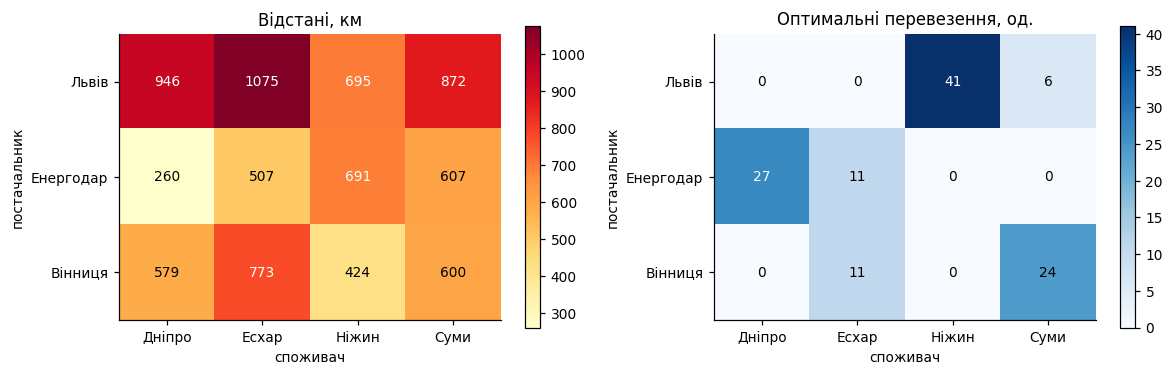

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, M, назва, cmap in [(axes[0], D, 'Відстані, км', 'YlOrRd'),
                           (axes[1], план_scipy, 'Оптимальні перевезення, од.', 'Blues')]:
    im = ax.imshow(M, cmap=cmap)
    ax.set_xticks(range(n))
    ax.set_xticklabels(споживачі)
    ax.set_yticks(range(m))
    ax.set_yticklabels(постачальники)
    ax.set_xlabel('споживач')
    ax.set_ylabel('постачальник')
    ax.set_title(назва)
    for i in range(m):                  
        for j in range(n):
            ax.text(j, i, '%.0f' % M[i, j], ha='center', va='center',
                    color='white' if M[i, j] > 0.6 * M.max() else 'black')
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

**Висновок:** Львів як найвіддаленіший постачальник везе майже все в найближчий для нього Ніжин, Енергодар закриває Дніпро по найкоротшому маршруту (260 км), а Вінниця, хоч для неї Ніжин теж найближчий, віддає його Львову і везе в Суми та Есхар, бо оптимум мінімізує загальну відстань, а не відстань кожного постачальника окремо.

---
# Етап 12. Декларація про використання інструментів штучного інтелекту

Користуватися мовними моделями **дозволено**. Обов'язковою є прозорість.
Порушенням є не використання інструмента, а нездатність пояснити власний код
і власні числа на захисті.

Для кожного етапу оберіть одне: `'ні'`, `'синтаксис'`, `'код, перевірено'`,
`'текст, перероблено'`, `'текст, як є'`.

In [19]:
ІНСТРУМЕНТИ_ШІ = 'Claude'     # напр. 'ChatGPT' або 'не використовував'

ДЕКЛАРАЦІЯ = {
    'етап 1, формалізація моделі':          'ні',
    'етап 2, побудова моделі в Excel':      'код, перевірено',
    'етап 3, код на Python':                'код, перевірено',
    'етапи 4–5, читання та перевірка звіту': 'синтаксис',
    'етап 6, рішення про закупівлю':        'код, перевірено',
    'етапи 7–8, перевірка та цілочисельність': 'код, перевірено',
    'етапи 9–11, транспортна задача':       'код, перевірено',
}

# Що саме ви перевірили за згенерованим кодом чи текстом — конкретно.
ЩО_ПЕРЕВІРЕНО = ("звірив план і прибуток Excel і Python (12334.67), перевірив, що +1 год різки дає рівно тіньову ціну 10.67, а закупівля 72.5 год дає +171.58, у транспортній задачі переконався, що вартість 69227 однакова, а тіньові ціни відрізняються на сталу 695, і з'ясував, що в PuLP 4.0 немає розв'язувача, тому перейшов на PuLP 3.3.2 з вбудованим CBC")

# True означає: я можу пояснити кожен рядок свого коду, відтворити будь-яке число
# цієї роботи та внести зміни в модель на вимогу під час захисту.
ПІДТВЕРДЖУЮ = True

In [20]:
# --- перевірка повноти декларації: клітинку не редагувати --------------------
ДОЗВОЛЕНІ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}
assert ІНСТРУМЕНТИ_ШІ.strip(), 'Вкажіть інструменти або напишіть «не використовував»'
порожні = [k for k, v in ДЕКЛАРАЦІЯ.items() if not str(v).strip()]
assert not порожні, 'Не заповнено: %s' % '; '.join(порожні)
чужі = {v for v in ДЕКЛАРАЦІЯ.values() if v not in ДОЗВОЛЕНІ}
assert not чужі, 'Недопустимі значення: %s' % ', '.join(sorted(чужі))
assert len(ЩО_ПЕРЕВІРЕНО.strip()) >= 120, ('Опишіть конкретніше (зараз %d символів, '
                                           'потрібно щонайменше 120)' % len(ЩО_ПЕРЕВІРЕНО.strip()))
assert ПІДТВЕРДЖУЮ is True, 'Підтвердьте, що можете пояснити власний код на захисті'
print('ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ')
print('=' * 78)
print('%-42s %s' % ('автор:', ПІБ))
print('%-42s %s' % ('інструменти:', ІНСТРУМЕНТИ_ШІ))
print('-' * 78)
for k, v in ДЕКЛАРАЦІЯ.items():
    print('%-42s %s' % (k + ':', v))
print('-' * 78)
print(ЩО_ПЕРЕВІРЕНО)

ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ
автор:                                     Левченко Денис
інструменти:                               Claude
------------------------------------------------------------------------------
етап 1, формалізація моделі:               ні
етап 2, побудова моделі в Excel:           код, перевірено
етап 3, код на Python:                     код, перевірено
етапи 4–5, читання та перевірка звіту:     синтаксис
етап 6, рішення про закупівлю:             код, перевірено
етапи 7–8, перевірка та цілочисельність:   код, перевірено
етапи 9–11, транспортна задача:            код, перевірено
------------------------------------------------------------------------------
звірив план і прибуток Excel і Python (12334.67), перевірив, що +1 год різки дає рівно тіньову ціну 10.67, а закупівля 72.5 год дає +171.58, у транспортній задачі переконався, що вартість 69227 однакова, а тіньові ціни відрізняються на сталу 695, і з'ясував, що в PuLP 4.0 немає розв'язувача, том

---
# Крок 13. Фінальна самоперевірка

In [21]:
перевірки = {
    'ПІБ і варіант заповнено':            bool(ПІБ) and 1 <= ВАРІАНТ <= 30,
    'Excel і Python дали однаковий план': abs(прибуток - EXCEL_ПРИБУТОК) < 0.5,
    'перевірку «ненульові = зв’язні» зроблено': ненульових == звязних,
    'дані транспортної задачі введено':   len(постачальники) == 3 and len(споживачі) == 4,
    'баланс запасів і попиту':            sum(запас) == sum(попит),
    'декларацію заповнено':               bool(ІНСТРУМЕНТИ_ШІ.strip()) and ПІДТВЕРДЖУЮ is True,
}
for k, v in перевірки.items():
    print(('OK   ' if v else 'НЕ ОК') + '  ' + k)
if all(перевірки.values()):
    print('\nТехнічна частина виконана.')
    print('Переконайтеся, що заповнені ВСІ клітинки з відповідями,')
    print('і виконайте Kernel → Restart & Run All перед здачею.')

OK     ПІБ і варіант заповнено
OK     Excel і Python дали однаковий план
OK     перевірку «ненульові = зв’язні» зроблено
OK     дані транспортної задачі введено
OK     баланс запасів і попиту
OK     декларацію заповнено

Технічна частина виконана.
Переконайтеся, що заповнені ВСІ клітинки з відповідями,
і виконайте Kernel → Restart & Run All перед здачею.
